In [54]:
%load_ext autoreload
%autoreload 2

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sksurv.nonparametric import kaplan_meier_estimator

from utils import (
    Model,
    bootstrap_compare,
    calibration_curve,
    evaluate,
    fit_categories,
    hazard_bandwidth,
    observed_hazard,
    population_hazard,
    remaining_life,
    tune,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
MODELS_DIR = "./models"
ARTIFACTS_DIR = "./artifacts"

In [56]:
FEATURES = [
    "model",
    "environment",
    "is_refurbished",
    "initial_battery_cycles",
    "firmware_major",
    "maintenance_interval_h",
    "operator_experience_yrs",
    "daily_utilization_h",
    "avg_flight_min",
    "avg_payload_kg",
    "payload_ratio",
    "mean_temp_c",
    "avg_humidity_pct",
    "avg_wind_ms",
    "hard_landings_per_100h",
    "mean_vibration_g",
]

CAT_FEATURES = ["model", "environment", "is_refurbished", "firmware_major"]

In [57]:
df = pd.read_csv("data/drone_survival.csv")

In [58]:
df.head()

,drone_id,model,environment,commission_date,is_refurbished,initial_battery_cycles,firmware_major,maintenance_interval_h,operator_experience_yrs,daily_utilization_h,...,avg_payload_kg,payload_ratio,mean_temp_c,avg_humidity_pct,avg_wind_ms,hard_landings_per_100h,mean_vibration_g,duration_h,event,failure_mode
0,DR-000000,hexa_heavy,urban,2024-08-12,False,22,5,50,3.93,3.42,...,3.886,0.389,-0.1,65.9,4.68,2.60,0.507,224.02,0,censored
1,DR-000001,quad_heavy,coastal,2025-01-06,False,25,4,50,3.99,1.06,...,4.166,0.833,23.7,65.2,5.16,2.72,0.678,380.54,0,censored
2,DR-000002,fixed_wing_vtol,coastal,2024-08-10,False,2,5,50,3.30,1.66,...,2.278,0.759,23.9,73.8,3.70,1.89,0.424,11.57,1,electronics
3,DR-000003,hexa_heavy,urban,2024-11-05,False,5,3,25,3.34,2.48,...,7.129,0.713,11.2,57.8,3.78,1.00,0.440,1044.08,0,censored
4,DR-000004,quad_light,urban,2025-04-25,False,8,4,200,2.11,1.63,...,0.335,0.335,19.2,54.7,6.20,1.63,0.367,63.67,1,crash


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   drone_id                 5000 non-null   str    
 1   model                    5000 non-null   str    
 2   environment              5000 non-null   str    
 3   commission_date          5000 non-null   str    
 4   is_refurbished           5000 non-null   bool   
 5   initial_battery_cycles   5000 non-null   int64  
 6   firmware_major           5000 non-null   int64  
 7   maintenance_interval_h   5000 non-null   int64  
 8   operator_experience_yrs  5000 non-null   float64
 9   daily_utilization_h      5000 non-null   float64
 10  avg_flight_min           5000 non-null   float64
 11  avg_payload_kg           5000 non-null   float64
 12  payload_ratio            5000 non-null   float64
 13  mean_temp_c              5000 non-null   float64
 14  avg_humidity_pct         5000 non-n

In [60]:
df["commission_date"] = pd.to_datetime(df["commission_date"])

t_val, t_test = df["commission_date"].quantile([0.70, 0.80])

train = df[df["commission_date"] < t_val]
val = df[(df["commission_date"] >= t_val) & (df["commission_date"] < t_test)]
test = df[df["commission_date"] >= t_test]
cats = fit_categories(train, CAT_FEATURES)

print(len(train) / len(df), len(val) / len(df), len(test) / len(df))
print(train["event"].mean(), val["event"].mean(), test["event"].mean())

0.6998 0.1 0.2002
0.6630465847384968 0.546 0.44755244755244755


In [61]:
N_TRIALS = 20

best_cox = tune("cox", train, val, N_TRIALS, FEATURES, CAT_FEATURES)
best_aft = tune("aft", train, val, N_TRIALS, FEATURES, CAT_FEATURES)

[I 2026-11-15 12:32:18,459] A new study created in memory with name: no-name-dd75c402-1416-4665-b84c-7b3ef8a1cbb7
[I 2026-11-15 12:32:18,647] Trial 0 finished with value: 0.12492833551332913 and parameters: {'max_depth': 3, 'eta': 0.13732181501427546, 'min_child_weight': 12.057126287443763, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'reg_lambda': 0.22853255256339203}. Best is trial 0 with value: 0.12492833551332913.
[I 2026-11-15 12:32:19,075] Trial 1 finished with value: 0.12355230062355467 and parameters: {'max_depth': 2, 'eta': 0.1180201220859558, 'min_child_weight': 7.725378389307352, 'subsample': 0.9124217733388136, 'colsample_bytree': 0.7061753482887407, 'reg_lambda': 17.052641538983092}. Best is trial 1 with value: 0.12355230062355467.
[I 2026-11-15 12:32:19,475] Trial 2 finished with value: 0.12360312013423598 and parameters: {'max_depth': 5, 'eta': 0.03657395726919529, 'min_child_weight': 1.8559980846490576, 'subsample': 0.7550213529560301, 'colsa

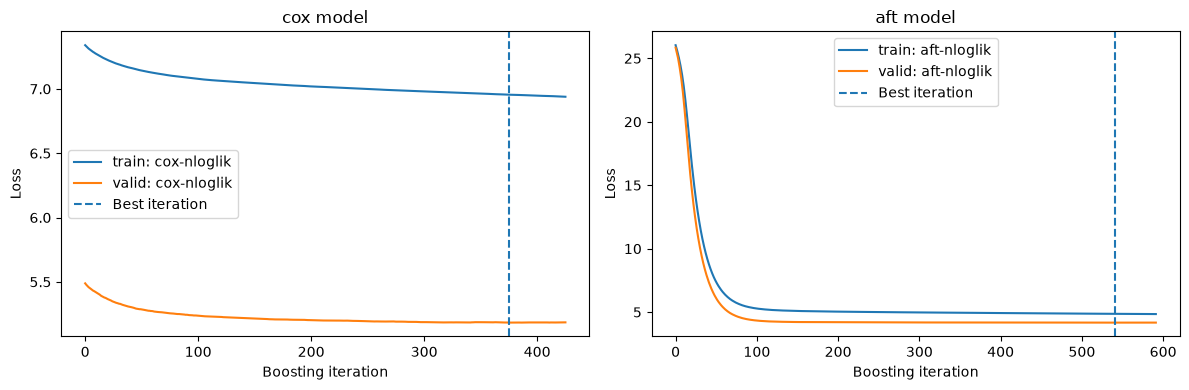

In [62]:
models = {"cox": best_cox, "aft": best_aft}

fig, axes = plt.subplots(1, len(models), figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    for split, metrics in model.history.items():
        for metric, values in metrics.items():
            ax.plot(values, label=f"{split}: {metric}")

    ax.axvline(model.booster.best_iteration, linestyle="--", label="Best iteration")
    ax.set_title(f"{name} model")
    ax.set_xlabel("Boosting iteration")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [63]:
os.makedirs(MODELS_DIR, exist_ok=True)

best_cox.save("./models/best_cox.json")
best_aft.save("./models/best_aft.json")

best_cox = Model.load("./models/best_cox.json")
best_aft = Model.load("./models/best_aft.json")

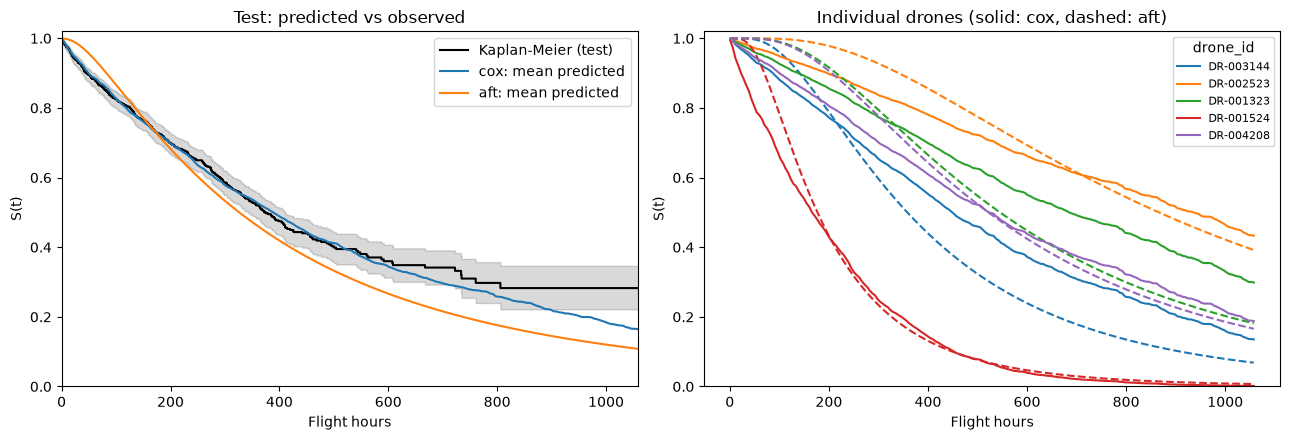

In [64]:
models = {"cox": best_cox, "aft": best_aft}

grid = np.linspace(1, np.quantile(train["duration_h"], 0.95), 200)
curves = {name: model.survival(test, grid) for name, model in models.items()}

km_time, km_surv, km_ci = kaplan_meier_estimator(
    test["event"].astype(bool), test["duration_h"], conf_type="log-log"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.step(km_time, km_surv, where="post", color="black", label="Kaplan-Meier (test)")
ax.fill_between(km_time, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, S in curves.items():
    ax.plot(grid, S.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title="Test: predicted vs observed",
    xlabel="Flight hours",
    ylabel="S(t)",
    xlim=(0, grid[-1]),
    ylim=(0, 1.02),
)
ax.legend()

ax = axes[1]
idx = np.random.default_rng(0).choice(len(test), size=5, replace=False)
for k, i in enumerate(idx):
    ax.plot(grid, curves["cox"][i], color=f"C{k}", label=test["drone_id"].iloc[i])
    ax.plot(grid, curves["aft"][i], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="S(t)",
    ylim=(0, 1.02),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

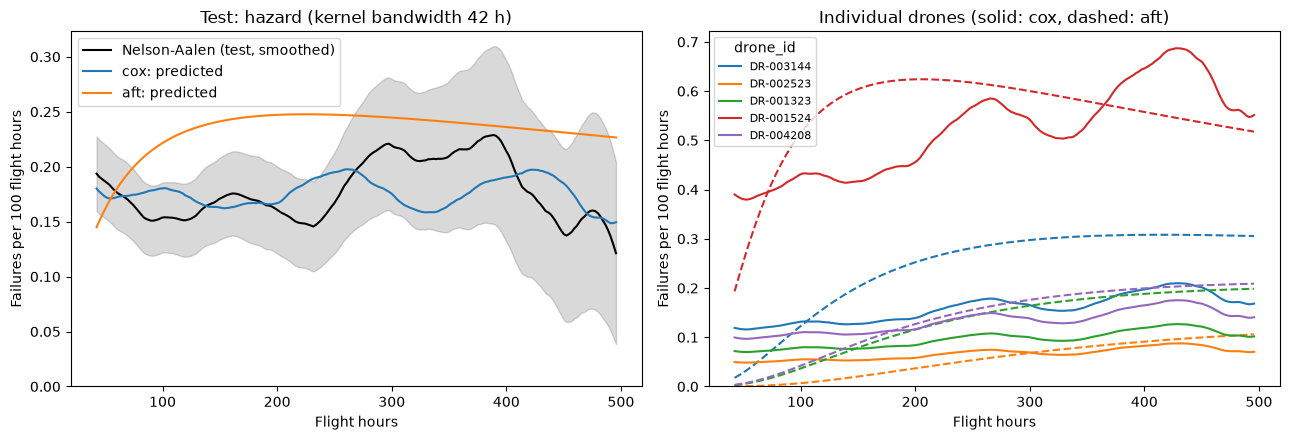

In [65]:
# Hazard h(t): failure rate among drones still flying at t, per 100 flight hours.
# Observed: kernel-smoothed Nelson-Aalen on test. Predicted: survival-weighted mean of
# the individual hazards over the same drones. The kernel loses mass near 0, so the
# grid starts one bandwidth in.
bandwidth = hazard_bandwidth(test["duration_h"], test["event"])
hz_grid = np.linspace(bandwidth, np.quantile(test["duration_h"], 0.9), 200)
hz_obs, hz_low, hz_high = observed_hazard(
    test["duration_h"], test["event"], hz_grid, bandwidth
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(hz_grid, 100 * hz_obs, color="black", label="Nelson-Aalen (test, smoothed)")
ax.fill_between(hz_grid, 100 * hz_low, 100 * hz_high, color="black", alpha=0.15)
for name, model in models.items():
    pop = population_hazard(model, test, hz_grid, bandwidth)
    ax.plot(hz_grid, 100 * pop, label=f"{name}: predicted")
ax.set(
    title=f"Test: hazard (kernel bandwidth {bandwidth:.0f} h)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend()

ax = axes[1]
sample = test.iloc[idx]
sample_hazard = {name: model.hazard(sample, hz_grid, bandwidth) for name, model in models.items()}
for k, drone_id in enumerate(sample["drone_id"]):
    ax.plot(hz_grid, 100 * sample_hazard["cox"][k], color=f"C{k}", label=drone_id)
    ax.plot(hz_grid, 100 * sample_hazard["aft"][k], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

In [66]:
# sksurv requires evaluation times inside each split's follow-up range
splits = {"val": val, "test": test}
eval_times = {
    name: np.linspace(*np.quantile(d["duration_h"], [0.05, 0.8]), 50)
    for name, d in splits.items()
}

results = {
    (model_name, split): evaluate(model, train, data, eval_times[split])
    for model_name, model in models.items()
    for split, data in splits.items()
}

SCALAR_METRICS = ["c_index", "c_index_ipcw", "mean_auc", "ibs"]
metrics = pd.DataFrame(
    {key: {m: r[m] for m in SCALAR_METRICS} for key, r in results.items()}
).T.rename_axis(["model", "split"])
metrics.round(4)

c_index  c_index_ipcw  mean_auc     ibs
model split                                         
cox   val     0.7314        0.7244    0.7842  0.1465
      test    0.6712        0.6700    0.6979  0.1446
aft   val     0.7309        0.7242    0.7917  0.1513
      test    0.6782        0.6765    0.7124  0.1488

In [67]:
# Select on validation IBS (the tuning objective); test is only reported
best_name = metrics.xs("val", level="split")["ibs"].idxmin()
best_model = models[best_name]

print(f"Best model by validation IBS: {best_name}")
metrics.xs("test", level="split").loc[[best_name]].round(4)

Best model by validation IBS: cox


,c_index,c_index_ipcw,mean_auc,ibs
model,,,,
cox,0.6712,0.67,0.6979,0.1446


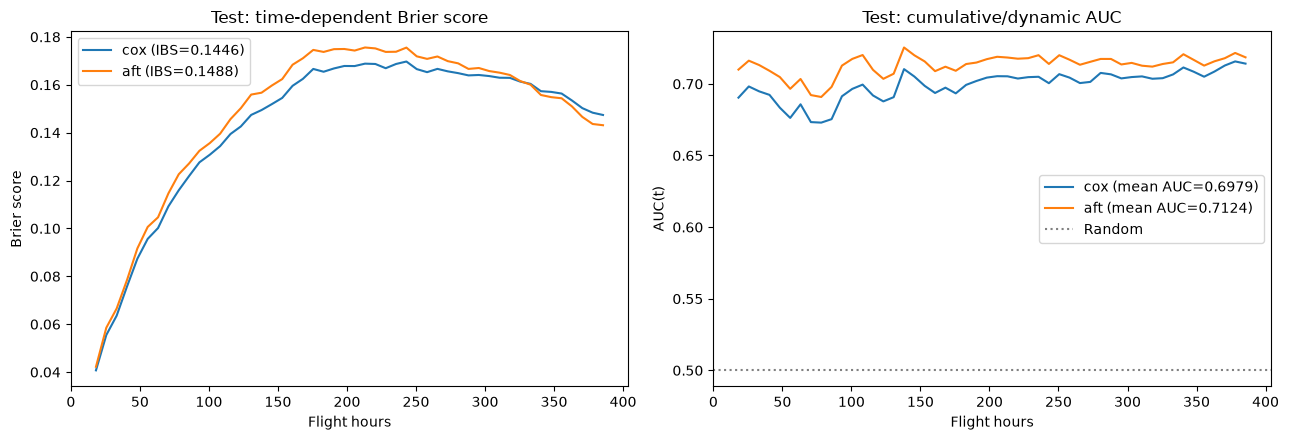

In [68]:
t = eval_times["test"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name in models:
    r = results[(name, "test")]
    axes[0].plot(t, r["brier"], label=f"{name} (IBS={r['ibs']:.4f})")
    axes[1].plot(t, r["auc"], label=f"{name} (mean AUC={r['mean_auc']:.4f})")

axes[0].set(
    title="Test: time-dependent Brier score",
    xlabel="Flight hours",
    ylabel="Brier score",
)
axes[1].axhline(0.5, color="grey", linestyle=":", label="Random")
axes[1].set(
    title="Test: cumulative/dynamic AUC", xlabel="Flight hours", ylabel="AUC(t)"
)
for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

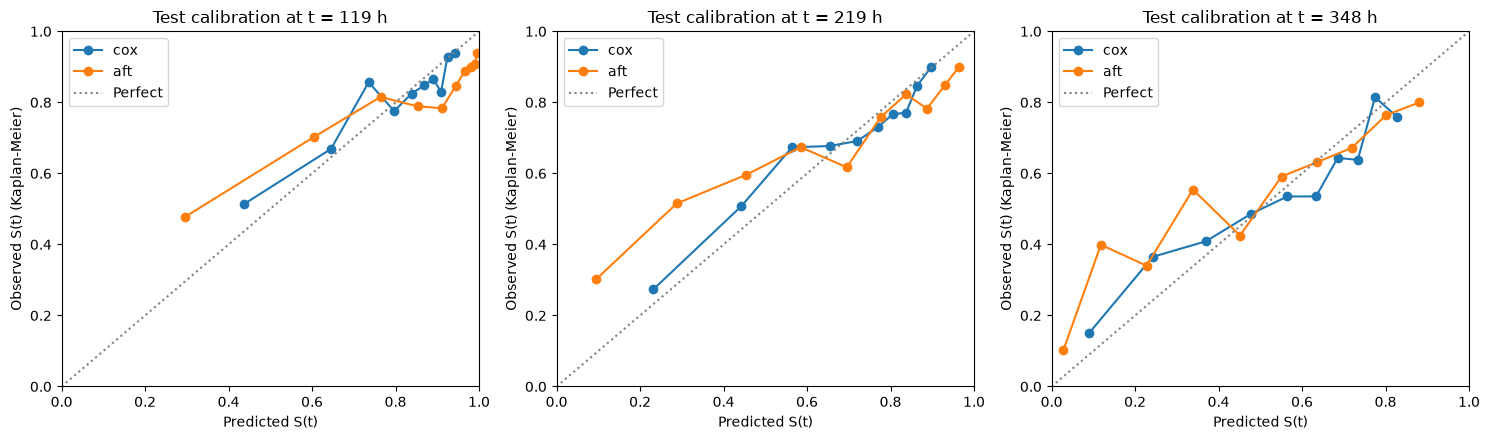

In [69]:
horizons = np.quantile(test["duration_h"], [0.25, 0.5, 0.75])
fig, axes = plt.subplots(1, len(horizons), figsize=(15, 4.5))

for ax, horizon in zip(axes, horizons):
    for name, model in models.items():
        cal = calibration_curve(model, test, horizon)
        ax.plot(cal["predicted"], cal["observed"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Perfect")
    ax.set(
        title=f"Test calibration at t = {horizon:.0f} h",
        xlabel="Predicted S(t)",
        ylabel="Observed S(t) (Kaplan-Meier)",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()

plt.tight_layout()
plt.show()

In [70]:
# Paired bootstrap on test: both models scored on the same resampled rows
boot_summary, boot_samples = bootstrap_compare(
    models, train, test, eval_times["test"], n_boot=1000, seed=42
)
boot_summary.round(4)

,model_a,model_b,metric,value_a,value_b,diff,ci_low,ci_high,p_value,better,significant
0,cox,aft,c_index,0.6712,0.6782,-0.0070,-0.0164,0.0025,0.158,aft,False
1,cox,aft,c_index_ipcw,0.6700,0.6765,-0.0065,-0.0158,0.0033,0.186,aft,False
2,cox,aft,mean_auc,0.6979,0.7124,-0.0146,-0.0257,-0.0034,0.024,aft,True
3,cox,aft,ibs,0.1446,0.1488,-0.0042,-0.0083,-0.0004,0.042,cox,True


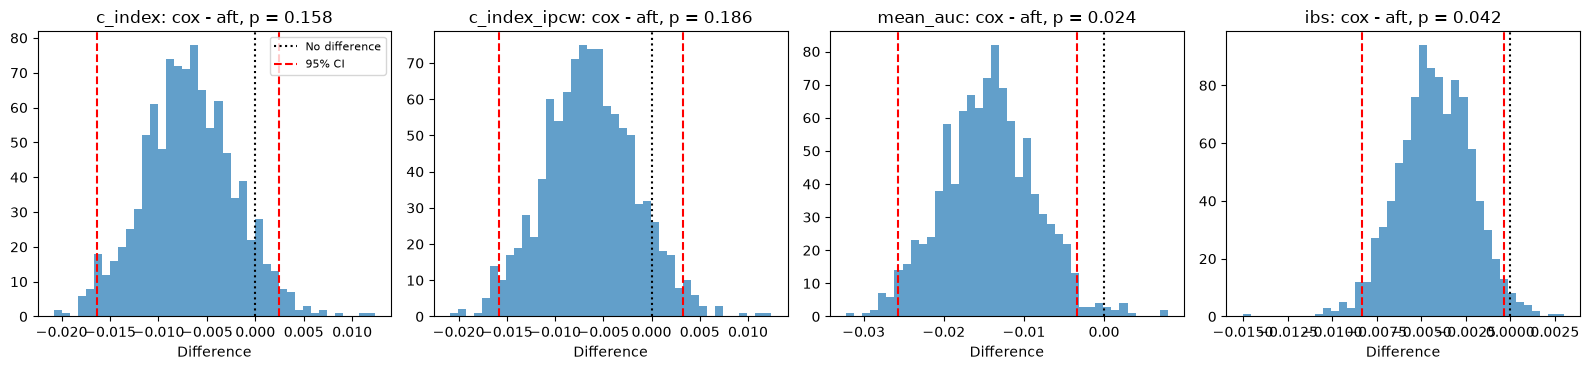

In [71]:
summary = boot_summary.set_index(["model_a", "model_b", "metric"])
a, b = "cox", "aft"

fig, axes = plt.subplots(1, len(SCALAR_METRICS), figsize=(16, 3.8))
for ax, metric in zip(axes, SCALAR_METRICS):
    row = summary.loc[(a, b, metric)]
    ax.hist(boot_samples[(a, metric)] - boot_samples[(b, metric)], bins=40, alpha=0.7)
    ax.axvline(0, color="black", linestyle=":", label="No difference")
    ax.axvline(row["ci_low"], color="red", linestyle="--", label="95% CI")
    ax.axvline(row["ci_high"], color="red", linestyle="--")
    ax.set(title=f"{metric}: {a} - {b}, p = {row['p_value']:.3f}", xlabel="Difference")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [72]:
# SHAP of the risk score on test: positive values push towards earlier failure.
# Cox is in log-HR units and AFT in log-time units, so compare shares, not raw values.
shap_values = {name: model.explain(test) for name, model in models.items()}

shap_importance = pd.DataFrame(
    {name: np.abs(e.values).mean(axis=0) for name, e in shap_values.items()},
    index=FEATURES,
).sort_values(best_name, ascending=False)
shap_share = shap_importance / shap_importance.sum()

pd.concat({"mean |SHAP|": shap_importance, "share": shap_share}, axis=1).round(4)

mean |SHAP|           share        
                                cox     aft     cox     aft
mean_temp_c                  0.3268  0.2484  0.2077  0.1660
avg_humidity_pct             0.1692  0.2022  0.1076  0.1351
initial_battery_cycles       0.1584  0.1176  0.1007  0.0786
firmware_major               0.1423  0.1661  0.0905  0.1110
environment                  0.1285  0.1664  0.0817  0.1112
operator_experience_yrs      0.1036  0.0952  0.0658  0.0636
avg_wind_ms                  0.0894  0.0901  0.0568  0.0602
hard_landings_per_100h       0.0859  0.1115  0.0546  0.0745
payload_ratio                0.0735  0.0588  0.0467  0.0393
mean_vibration_g             0.0701  0.0556  0.0446  0.0372
avg_payload_kg               0.0531  0.0298  0.0337  0.0199
maintenance_interval_h       0.0481  0.0325  0.0305  0.0217
avg_flight_min               0.0442  0.0453  0.0281  0.0303
daily_utilization_h          0.0331  0.0477  0.0211  0.0319
model                        0.0238  0.0133  0.0151  0.0089
is_refurbished               0.0233  0.0161  0.0148  0.0107

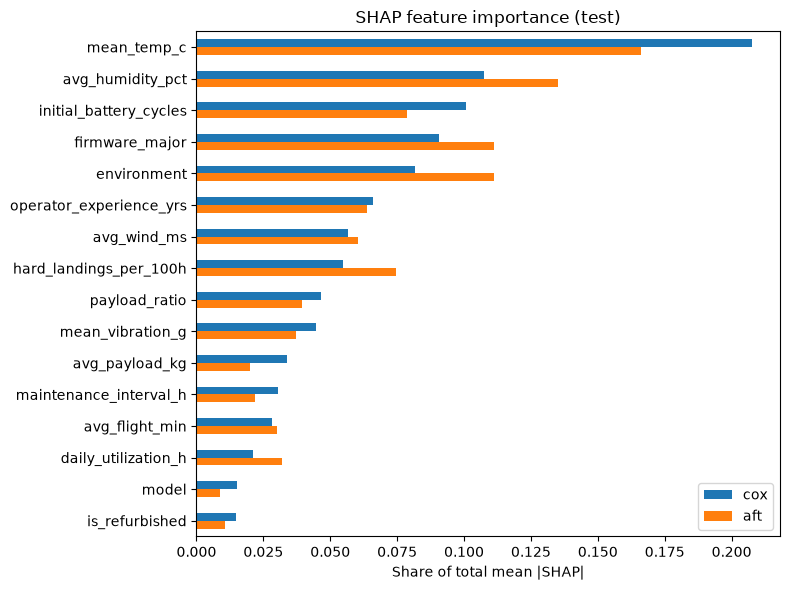

In [73]:
ax = shap_share.plot.barh(figsize=(8, 6))
ax.invert_yaxis()
ax.set(title="SHAP feature importance (test)", xlabel="Share of total mean |SHAP|")
plt.tight_layout()
plt.show()

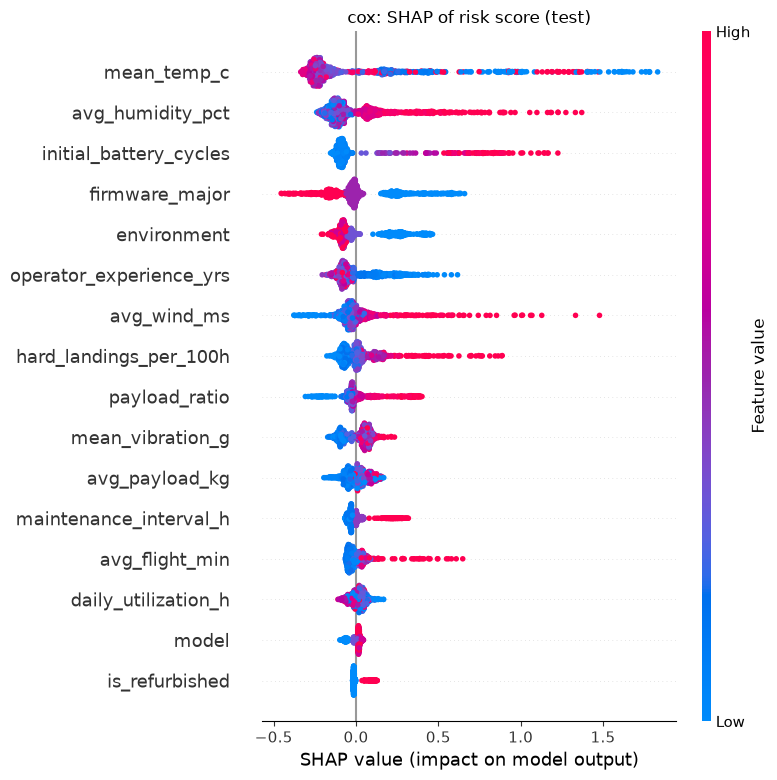

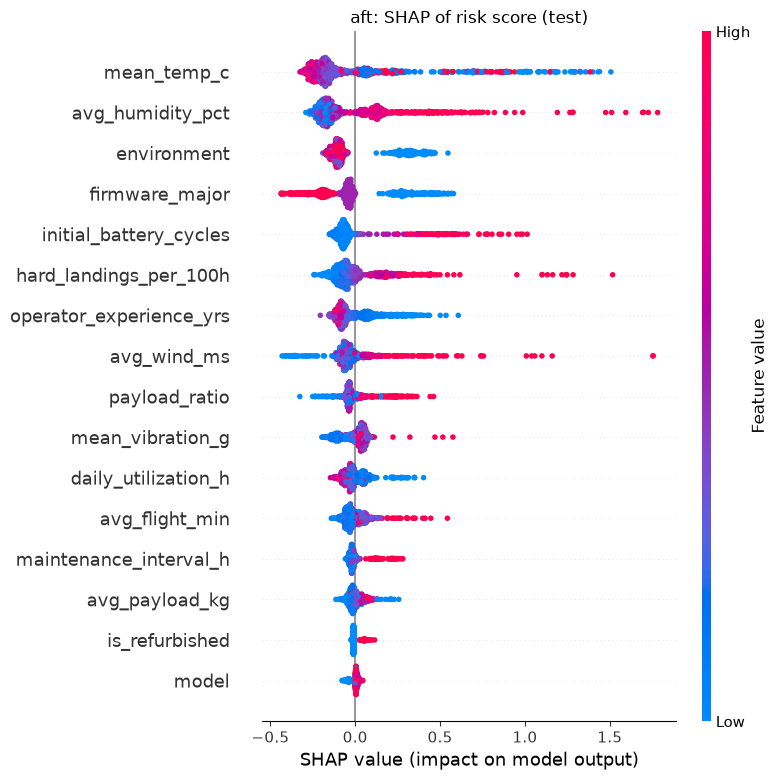

In [74]:
for name, explanation in shap_values.items():
    shap.plots.beeswarm(explanation, max_display=len(FEATURES), show=False)
    plt.title(f"{name}: SHAP of risk score (test)")
    plt.tight_layout()
    plt.show()

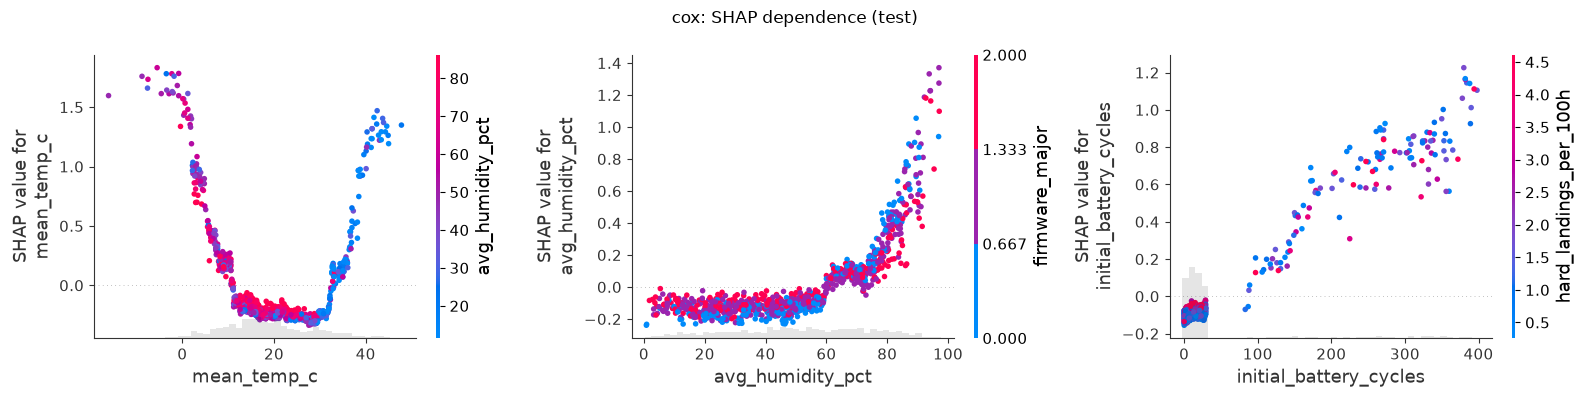

In [75]:
# Dependence plots for the best model's top features (categoricals shown as codes)
top_features = shap_importance.index[:3]
fig, axes = plt.subplots(1, len(top_features), figsize=(16, 4))
for ax, feature in zip(axes, top_features):
    shap.plots.scatter(
        shap_values[best_name][:, feature],
        color=shap_values[best_name],
        ax=ax,
        show=False,
    )
fig.suptitle(f"{best_name}: SHAP dependence (test)")
plt.tight_layout()
plt.show()

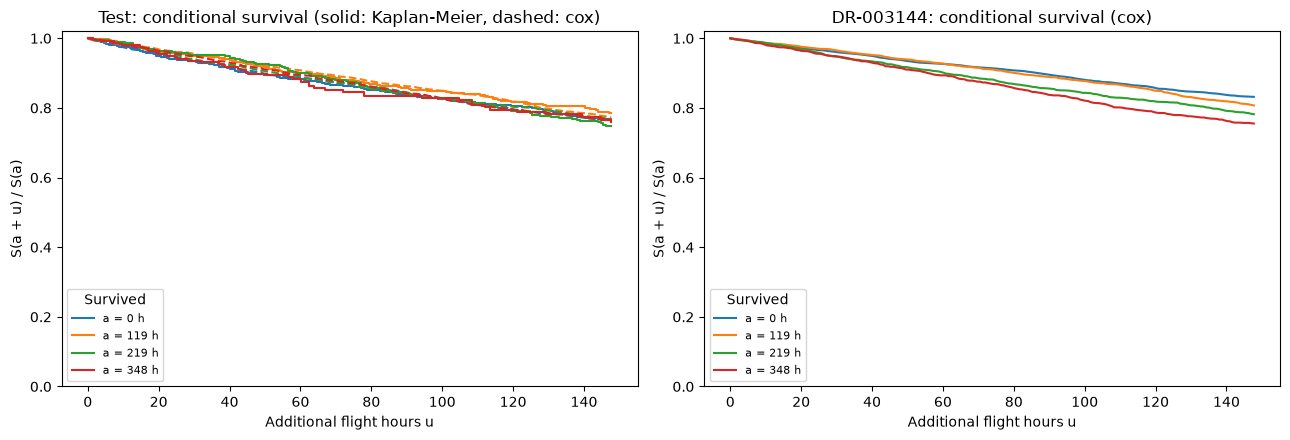

,age_h,observed P(fail in 100 h),cox P(fail in 100 h)
0,0.0,0.175,0.175
1,119.0,0.152,0.151
2,219.0,0.175,0.171
3,348.0,0.171,0.173


In [76]:
# Conditional survival S(a + u | T > a) = S(a + u) / S(a) = exp(-integral of h over
# [a, a + u]): the outlook of a drone that has already flown a hours. A flat hazard
# gives the same curve at every age; a rising one makes older drones' curves fall faster.
# Group level: observed is Kaplan-Meier S(a + u) / S(a); predicted is
# sum S_i(a + u) / sum S_i(a) (drones that failed before a drop out).
cond_ages = np.r_[0.0, np.quantile(test["duration_h"], [0.25, 0.5, 0.75])].round()
cond_grid = np.linspace(0, np.quantile(test["duration_h"], 0.9) - cond_ages[-1], 200)


def km_survival(times: np.ndarray) -> np.ndarray:
    """Test Kaplan-Meier at ``times`` (step function, 1 before the first event)."""
    i = np.searchsorted(km_time, times, side="right") - 1
    return np.where(i >= 0, km_surv[np.maximum(i, 0)], 1.0)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
test_surv = best_model.survival(test, np.r_[cond_ages, np.add.outer(cond_ages, cond_grid).ravel()])
s_age = test_surv[:, : len(cond_ages)].sum(axis=0)
s_ahead = test_surv[:, len(cond_ages) :].sum(axis=0).reshape(len(cond_ages), -1)
window_rows = []
for k, a in enumerate(cond_ages):
    observed = km_survival(a + cond_grid) / km_survival(a)
    predicted = s_ahead[k] / s_age[k]
    ax.step(cond_grid, observed, where="post", color=f"C{k}", label=f"a = {a:.0f} h")
    ax.plot(cond_grid, predicted, color=f"C{k}", linestyle="--")
    window_rows.append(
        {
            "age_h": a,
            "observed P(fail in 100 h)": 1 - km_survival(a + 100) / km_survival(a),
            f"{best_name} P(fail in 100 h)": 1 - np.interp(100, cond_grid, predicted),
        }
    )
ax.set(
    title=f"Test: conditional survival (solid: Kaplan-Meier, dashed: {best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

ax = axes[1]
drone = test.iloc[[idx[0]]]
drone_curves = best_model.conditional_survival(
    pd.concat([drone] * len(cond_ages)), cond_ages, cond_grid
)
for k, (a, s) in enumerate(zip(cond_ages, drone_curves)):
    ax.plot(cond_grid, s, color=f"C{k}", label=f"a = {a:.0f} h")
ax.set(
    title=f"{drone['drone_id'].iloc[0]}: conditional survival ({best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

plt.tight_layout()
plt.show()

pd.DataFrame(window_rows).round(3)

In [77]:
# Drones in service: censored test drones, current age = duration_h.
# Assumes censoring is mostly administrative (still flying at the data cut-off).
active = test[test["event"] == 0]

# Keep age + horizon inside the Cox baseline support (flat after the last training event)
last_train_event = train.loc[train["event"] == 1, "duration_h"].max()
horizon = np.floor(last_train_event - active["duration_h"].max())

rul = remaining_life(best_model, active, horizon=horizon, window=100)
print(f"Model: {best_name}, horizon: {horizon:.0f} h, drones in service: {len(rul)}")
rul.sort_values("p_fail_window", ascending=False).head(10).round(3)

Model: cox, horizon: 1111 h, drones in service: 553


,drone_id,age_h,rul_q10,rul_median,rmrl,p_fail_window
3580,DR-003580,463.74,4.444,33.330,41.402,0.937
2709,DR-002709,336.16,9.999,44.440,57.199,0.841
3057,DR-003057,193.50,8.888,54.439,78.186,0.720
3616,DR-003616,145.55,11.110,72.215,92.897,0.650
2646,DR-002646,358.50,14.443,81.103,118.065,0.588
751,DR-000751,59.10,16.665,82.214,109.255,0.570
434,DR-000434,199.29,16.665,86.658,120.219,0.562
3906,DR-003906,422.17,12.221,92.213,124.500,0.548
4598,DR-004598,432.00,12.221,86.658,119.823,0.540
2367,DR-002367,227.76,14.443,93.324,129.181,0.530


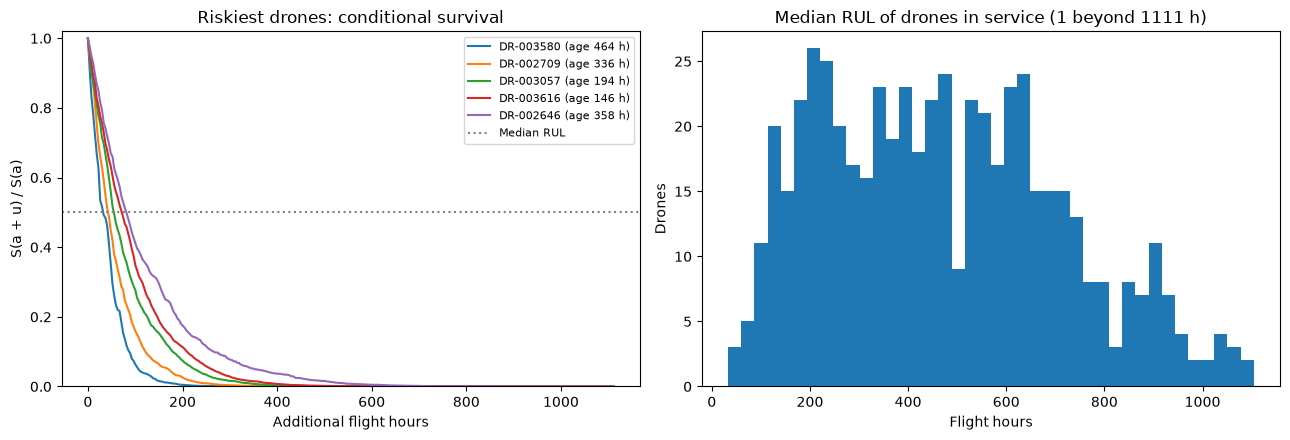

In [78]:
rul_grid = np.linspace(0, horizon, 300)
riskiest = rul.nlargest(5, "p_fail_window").index
rul_curves = best_model.conditional_survival(
    active.loc[riskiest], active.loc[riskiest, "duration_h"], rul_grid
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
for k, (idx, s) in enumerate(zip(riskiest, rul_curves)):
    label = f"{active.at[idx, 'drone_id']} (age {active.at[idx, 'duration_h']:.0f} h)"
    ax.plot(rul_grid, s, color=f"C{k}", label=label)
ax.axhline(0.5, color="grey", linestyle=":", label="Median RUL")
ax.set(
    title="Riskiest drones: conditional survival",
    xlabel="Additional flight hours",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(fontsize=8)

ax = axes[1]
finite = np.isfinite(rul["rul_median"])
ax.hist(rul.loc[finite, "rul_median"], bins=40)
ax.set(
    title=f"Median RUL of drones in service ({(~finite).sum()} beyond {horizon:.0f} h)",
    xlabel="Flight hours",
    ylabel="Drones",
)

plt.tight_layout()
plt.show()

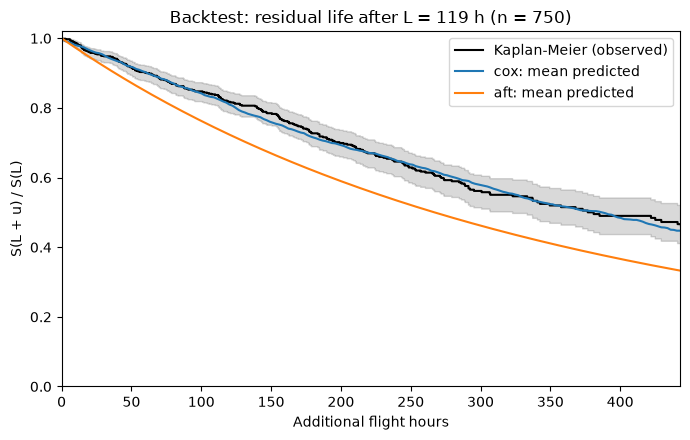

In [79]:
# Backtest: test drones still at risk at landmark L. Their observed residual life
# (Kaplan-Meier) should match the mean predicted conditional survival.
landmark = np.quantile(test["duration_h"], 0.25)
at_risk = test[test["duration_h"] > landmark]
residual = at_risk["duration_h"] - landmark

km_t, km_s, km_ci = kaplan_meier_estimator(
    at_risk["event"].astype(bool), residual, conf_type="log-log"
)
u = np.linspace(0, residual.quantile(0.9), 200)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.step(km_t, km_s, where="post", color="black", label="Kaplan-Meier (observed)")
ax.fill_between(km_t, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, model in models.items():
    pred = model.conditional_survival(at_risk, np.full(len(at_risk), landmark), u)
    ax.plot(u, pred.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title=f"Backtest: residual life after L = {landmark:.0f} h (n = {len(at_risk)})",
    xlabel="Additional flight hours",
    ylabel="S(L + u) / S(L)",
    xlim=(0, u[-1]),
    ylim=(0, 1.02),
)
ax.legend()
plt.tight_layout()
plt.show()

In [80]:
# Persist everything the dashboard needs; the fitted models are already in MODELS_DIR.
os.makedirs(ARTIFACTS_DIR, exist_ok=True)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_parquet(os.path.join(ARTIFACTS_DIR, f"{name}.parquet"), index=False)


save_table(metrics.reset_index(), "metrics")

save_table(
    pd.concat(
        pd.DataFrame(
            {
                "model": name,
                "t": eval_times["test"],
                "brier": results[(name, "test")]["brier"],
                "auc": results[(name, "test")]["auc"],
            }
        )
        for name in models
    ),
    "brier_auc",
)

save_table(
    pd.concat(
        calibration_curve(model, test, h).assign(model=name, horizon=h)
        for name, model in models.items()
        for h in horizons
    ),
    "calibration",
)

save_table(boot_summary, "bootstrap_summary")
save_table(
    pd.concat(
        pd.DataFrame(
            {
                "iteration": boot_samples.index,
                "model": model_name,
                "metric": metric,
                "value": boot_samples[(model_name, metric)].to_numpy(),
            }
        )
        for model_name, metric in boot_samples.columns
    ),
    "bootstrap_samples",
)

# SHAP in long format: one row per (drone, model, feature)
n_features = len(FEATURES)
save_table(
    pd.concat(
        pd.DataFrame(
            {
                "drone_id": np.repeat(test["drone_id"].to_numpy(), n_features),
                "model": name,
                "feature": np.tile(e.feature_names, len(test)),
                "shap": e.values.ravel(),
                "value": e.data.ravel(),
                "display": test[e.feature_names].astype(str).to_numpy().ravel(),
            }
        )
        for name, e in shap_values.items()
    ),
    "shap_values",
)
importance = shap_importance.reset_index(names="feature").melt(
    id_vars="feature", var_name="model", value_name="mean_abs_shap"
)
importance["share"] = importance["mean_abs_shap"] / importance.groupby("model")[
    "mean_abs_shap"
].transform("sum")
save_table(importance, "shap_importance")

# Per-drone predictions. risk_group: terciles of the best model's risk over all test
# drones; priority: maintenance urgency of drones in service by p_fail_window.
PRIORITY_HIGH, PRIORITY_MEDIUM = 0.5, 0.2
predictions = test.copy()
for name, model in models.items():
    predictions[f"risk_{name}"] = model.risk(test)
predictions["risk_group"] = pd.qcut(
    predictions[f"risk_{best_name}"], 3, labels=["Low", "Medium", "High"]
).astype(str)
predictions = predictions.join(rul.drop(columns=["drone_id"]))
predictions["priority"] = np.select(
    [
        predictions["p_fail_window"] >= PRIORITY_HIGH,
        predictions["p_fail_window"] >= PRIORITY_MEDIUM,
        predictions["p_fail_window"].notna(),
    ],
    ["High", "Medium", "Low"],
    default="None (failed)",
)
save_table(predictions, "predictions")

# Mean predicted survival vs Kaplan-Meier on test, and the landmark backtest.
# Kaplan-Meier is recomputed here because later cells reuse the km_* names.
km_test = kaplan_meier_estimator(
    test["event"].astype(bool), test["duration_h"], conf_type="log-log"
)
km_backtest = kaplan_meier_estimator(
    at_risk["event"].astype(bool), residual, conf_type="log-log"
)
save_table(
    pd.concat(
        [
            pd.DataFrame(
                {
                    "source": "km",
                    "t": km_test[0],
                    "s": km_test[1],
                    "ci_low": km_test[2][0],
                    "ci_high": km_test[2][1],
                }
            ),
            *(
                pd.DataFrame({"source": name, "t": grid, "s": s.mean(axis=0)})
                for name, s in curves.items()
            ),
        ]
    ),
    "survival_mean",
)
save_table(
    pd.concat(
        [
            pd.DataFrame(
                {
                    "source": "km",
                    "u": km_backtest[0],
                    "s": km_backtest[1],
                    "ci_low": km_backtest[2][0],
                    "ci_high": km_backtest[2][1],
                }
            ),
            *(
                pd.DataFrame(
                    {
                        "source": name,
                        "u": u,
                        "s": model.conditional_survival(
                            at_risk, np.full(len(at_risk), landmark), u
                        ).mean(axis=0),
                    }
                )
                for name, model in models.items()
            ),
        ]
    ),
    "backtest",
)

numeric_features = [f for f in FEATURES if f not in cats and f != "is_refurbished"]
meta = {
    "generated_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "best_name": best_name,
    "models": {name: f"best_{name}.json" for name in models},
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "categories": cats,
    "numeric_ranges": {
        f: [float(train[f].min()), float(train[f].max())] for f in numeric_features
    },
    "split": {"t_val": str(t_val.date()), "t_test": str(t_test.date())},
    "n_trials": N_TRIALS,
    "n_boot": len(boot_samples),
    "eval_times": {k: v.tolist() for k, v in eval_times.items()},
    "calibration_horizons": [float(h) for h in horizons],
    "rul_horizon": float(horizon),
    "rul_window": 100,
    "landmark": float(landmark),
    "priority_thresholds": {"high": PRIORITY_HIGH, "medium": PRIORITY_MEDIUM},
    "shap_base": {name: float(e.base_values[0]) for name, e in shap_values.items()},
}
with open(os.path.join(ARTIFACTS_DIR, "meta.json"), "w") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

sorted(os.listdir(ARTIFACTS_DIR))

['backtest.parquet',
 'bootstrap_samples.parquet',
 'bootstrap_summary.parquet',
 'brier_auc.parquet',
 'calibration.parquet',
 'meta.json',
 'metrics.parquet',
 'predictions.parquet',
 'shap_importance.parquet',
 'shap_values.parquet',
 'survival_mean.parquet']